# 01 · RAG from scratch

Before using any framework, we'll build the whole RAG loop by hand in about 50 lines: embed
some passages, find the closest ones with a bit of numpy, and paste them into a prompt.

**In this notebook you will:**
- see the model fail on a question it can't know,
- compute cosine similarity yourself and retrieve the top passages,
- build the augmented prompt and watch the same question get answered correctly,
- see what happens when the answer isn't in the passages.

In [1]:
# Setup 1/3: find the project and your API key. Works locally, in Google Colab and in Kaggle.
# (You don't need to read this cell; it is identical in every notebook.)
import importlib.util, os, subprocess, sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
REPO_URL = os.environ.get("RAGLAB_REPO_URL", "")  # set this to the public GitHub URL when running in the cloud


def find_repo_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "pyproject.toml").exists() and (folder / "raglab").is_dir():
            return folder
    return None


ROOT = find_repo_root()
if ROOT is None and (IN_COLAB or IN_KAGGLE):
    if not REPO_URL:
        print("Set REPO_URL (or the RAGLAB_REPO_URL env var) to this project's GitHub URL, then re-run this cell.")
    else:
        ROOT = Path("/content/RAG-lab" if IN_COLAB else "/kaggle/working/RAG-lab")
        if not ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
    try:  # read the key from the platform's secret store
        if IN_COLAB:
            from google.colab import userdata
            os.environ.setdefault("OPENAI_API_KEY", userdata.get("OPENAI_API_KEY") or "")
        else:
            from kaggle_secrets import UserSecretsClient
            os.environ.setdefault("OPENAI_API_KEY", UserSecretsClient().get_secret("OPENAI_API_KEY") or "")
    except Exception:
        print("Add OPENAI_API_KEY to this notebook's secrets (Colab: key icon on the left; Kaggle: Add-ons > Secrets).")

if ROOT is not None and str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from raglab.config import get_settings

settings = get_settings()
if settings.openai_api_key:
    print(f"Project: {ROOT.name if ROOT else '?'} | chat model: {settings.chat_model} | embeddings: {settings.embed_model}")
else:
    print("No OPENAI_API_KEY found. Copy .env.example to .env and paste your key, then restart the kernel.")

Project: RAG-lab | chat model: gpt-6-luna | embeddings: text-embedding-3-small


In [2]:
# Setup 2/3: nothing to prepare. This notebook uses 8 short passages written below.

In [3]:
# Setup 3/3: start the cost meter at zero
from raglab.llm import cost

cost.reset()

## 1. Without retrieval, the model guesses

Token Hotels & Resorts is fictional, so the model has never seen its documents.

In [4]:
from raglab import llm

question = "What time is check-in at Token Kyoto?"
print(llm.chat(question))

Check-in at Token Kyoto is from 3:00 PM.


Whatever it says, it can't be grounded in Token's real policy. Now let's give it the facts.

## 2. A tiny knowledge base

Real documents are long; we'll get to loading and chunking them in notebook 02. For now,
here are eight short passages, the kind of chunks a real pipeline would produce.

In [5]:
passages = [
    "Check-in at Token Lisbon starts at 3:00 PM and check-out is at 11:00 AM. Guests can use a heated rooftop pool.",
    "Check-in at Token Kyoto starts at 4:00 PM and check-out is at 11:00 AM. The hotel has a private onsen-style spa.",
    "Token Vancouver has 210 rooms, an indoor saltwater pool and a full-service spa. Check-in starts at 3:30 PM.",
    "Hanare at Token Kyoto serves kaiseki. Reservations are required at least 3 days ahead.",
    "Token Singapore is the group's flagship tower on Marina Bay, with a 60-metre infinity pool on the 52nd floor.",
    "Wi-Fi is free for every guest at every Token Hotels & Resorts property.",
    "Token Cusco sits at 3,400 metres. Pickup from Cusco airport is free, and coca tea is served on arrival.",
    "Token Circle members earn 10 points for every dollar spent; 10,000 points buy one free night.",
]
len(passages)

8

## 3. Embed everything once

Each passage becomes a vector. We stack them into a matrix with one row per passage.

In [6]:
import numpy as np

passage_vecs = np.array(llm.embed(passages))
print(passage_vecs.shape)  # (number of passages, dimensions)

(8, 1536)


## 4. Cosine similarity, by hand

Two vectors are similar when they point in the same direction. **Cosine similarity** is the
cosine of the angle between them:

$$\text{cos}(q, d) = \frac{q \cdot d}{\lVert q \rVert \, \lVert d \rVert}$$

If we first scale every vector to length 1, it's just a dot product, and one matrix
multiplication scores the question against every passage at once.

In [7]:
question_vec = np.array(llm.embed_one(question))

q = question_vec / np.linalg.norm(question_vec)
m = passage_vecs / np.linalg.norm(passage_vecs, axis=1, keepdims=True)
scores = m @ q

import pandas as pd

table = pd.DataFrame({"score": scores.round(3), "passage": [p[:80] + "…" for p in passages]})
table.sort_values("score", ascending=False)

,score,passage
1,0.821,Check-in at Token Kyoto starts at 4:00 PM and ...
0,0.534,Check-in at Token Lisbon starts at 3:00 PM and...
3,0.516,Hanare at Token Kyoto serves kaiseki. Reservat...
2,0.412,"Token Vancouver has 210 rooms, an indoor saltw..."
5,0.331,Wi-Fi is free for every guest at every Token H...
6,0.254,"Token Cusco sits at 3,400 metres. Pickup from ..."
7,0.244,Token Circle members earn 10 points for every ...
4,0.178,Token Singapore is the group's flagship tower ...


The Kyoto check-in passage wins clearly. Next come the Lisbon check-in passage (same *topic*,
different hotel) and the Kyoto restaurant passage (same *hotel*, different topic). Passages about
Wi-Fi, loyalty points or Singapore score lowest.

## 5. Retrieve the top 3

`raglab.scratch` wraps the same maths in two small functions, `cosine_sim` and `top_k`:

In [8]:
from raglab import scratch

hits = scratch.top_k(question_vec, passage_vecs, k=3)
for index, score in hits:
    print(f"{score:.3f}  {passages[index]}")

0.821  Check-in at Token Kyoto starts at 4:00 PM and check-out is at 11:00 AM. The hotel has a private onsen-style spa.
0.534  Check-in at Token Lisbon starts at 3:00 PM and check-out is at 11:00 AM. Guests can use a heated rooftop pool.
0.516  Hanare at Token Kyoto serves kaiseki. Reservations are required at least 3 days ahead.


## 6. Augment the prompt and generate

"Augmented generation" just means pasting the retrieved passages into the prompt and telling
the model to stick to them. Here is the full prompt the model will see:

In [9]:
contexts = [passages[i] for i, _ in hits]
prompt = scratch.build_prompt(question, contexts)
print(prompt)

You are a concierge for Token Hotels & Resorts.
Answer the question using only the numbered passages below.
If the passages do not contain the answer, say "I don't know based on these passages."

Passages:
[1] Check-in at Token Kyoto starts at 4:00 PM and check-out is at 11:00 AM. The hotel has a private onsen-style spa.
[2] Check-in at Token Lisbon starts at 3:00 PM and check-out is at 11:00 AM. Guests can use a heated rooftop pool.
[3] Hanare at Token Kyoto serves kaiseki. Reservations are required at least 3 days ahead.

Question: What time is check-in at Token Kyoto?
Answer:


In [10]:
print(llm.chat(prompt))

Check-in at Token Kyoto starts at 4:00 PM.


Same model, same question, now a correct, grounded answer. **That's all RAG is.**

Here's the flow we just ran, step by step:

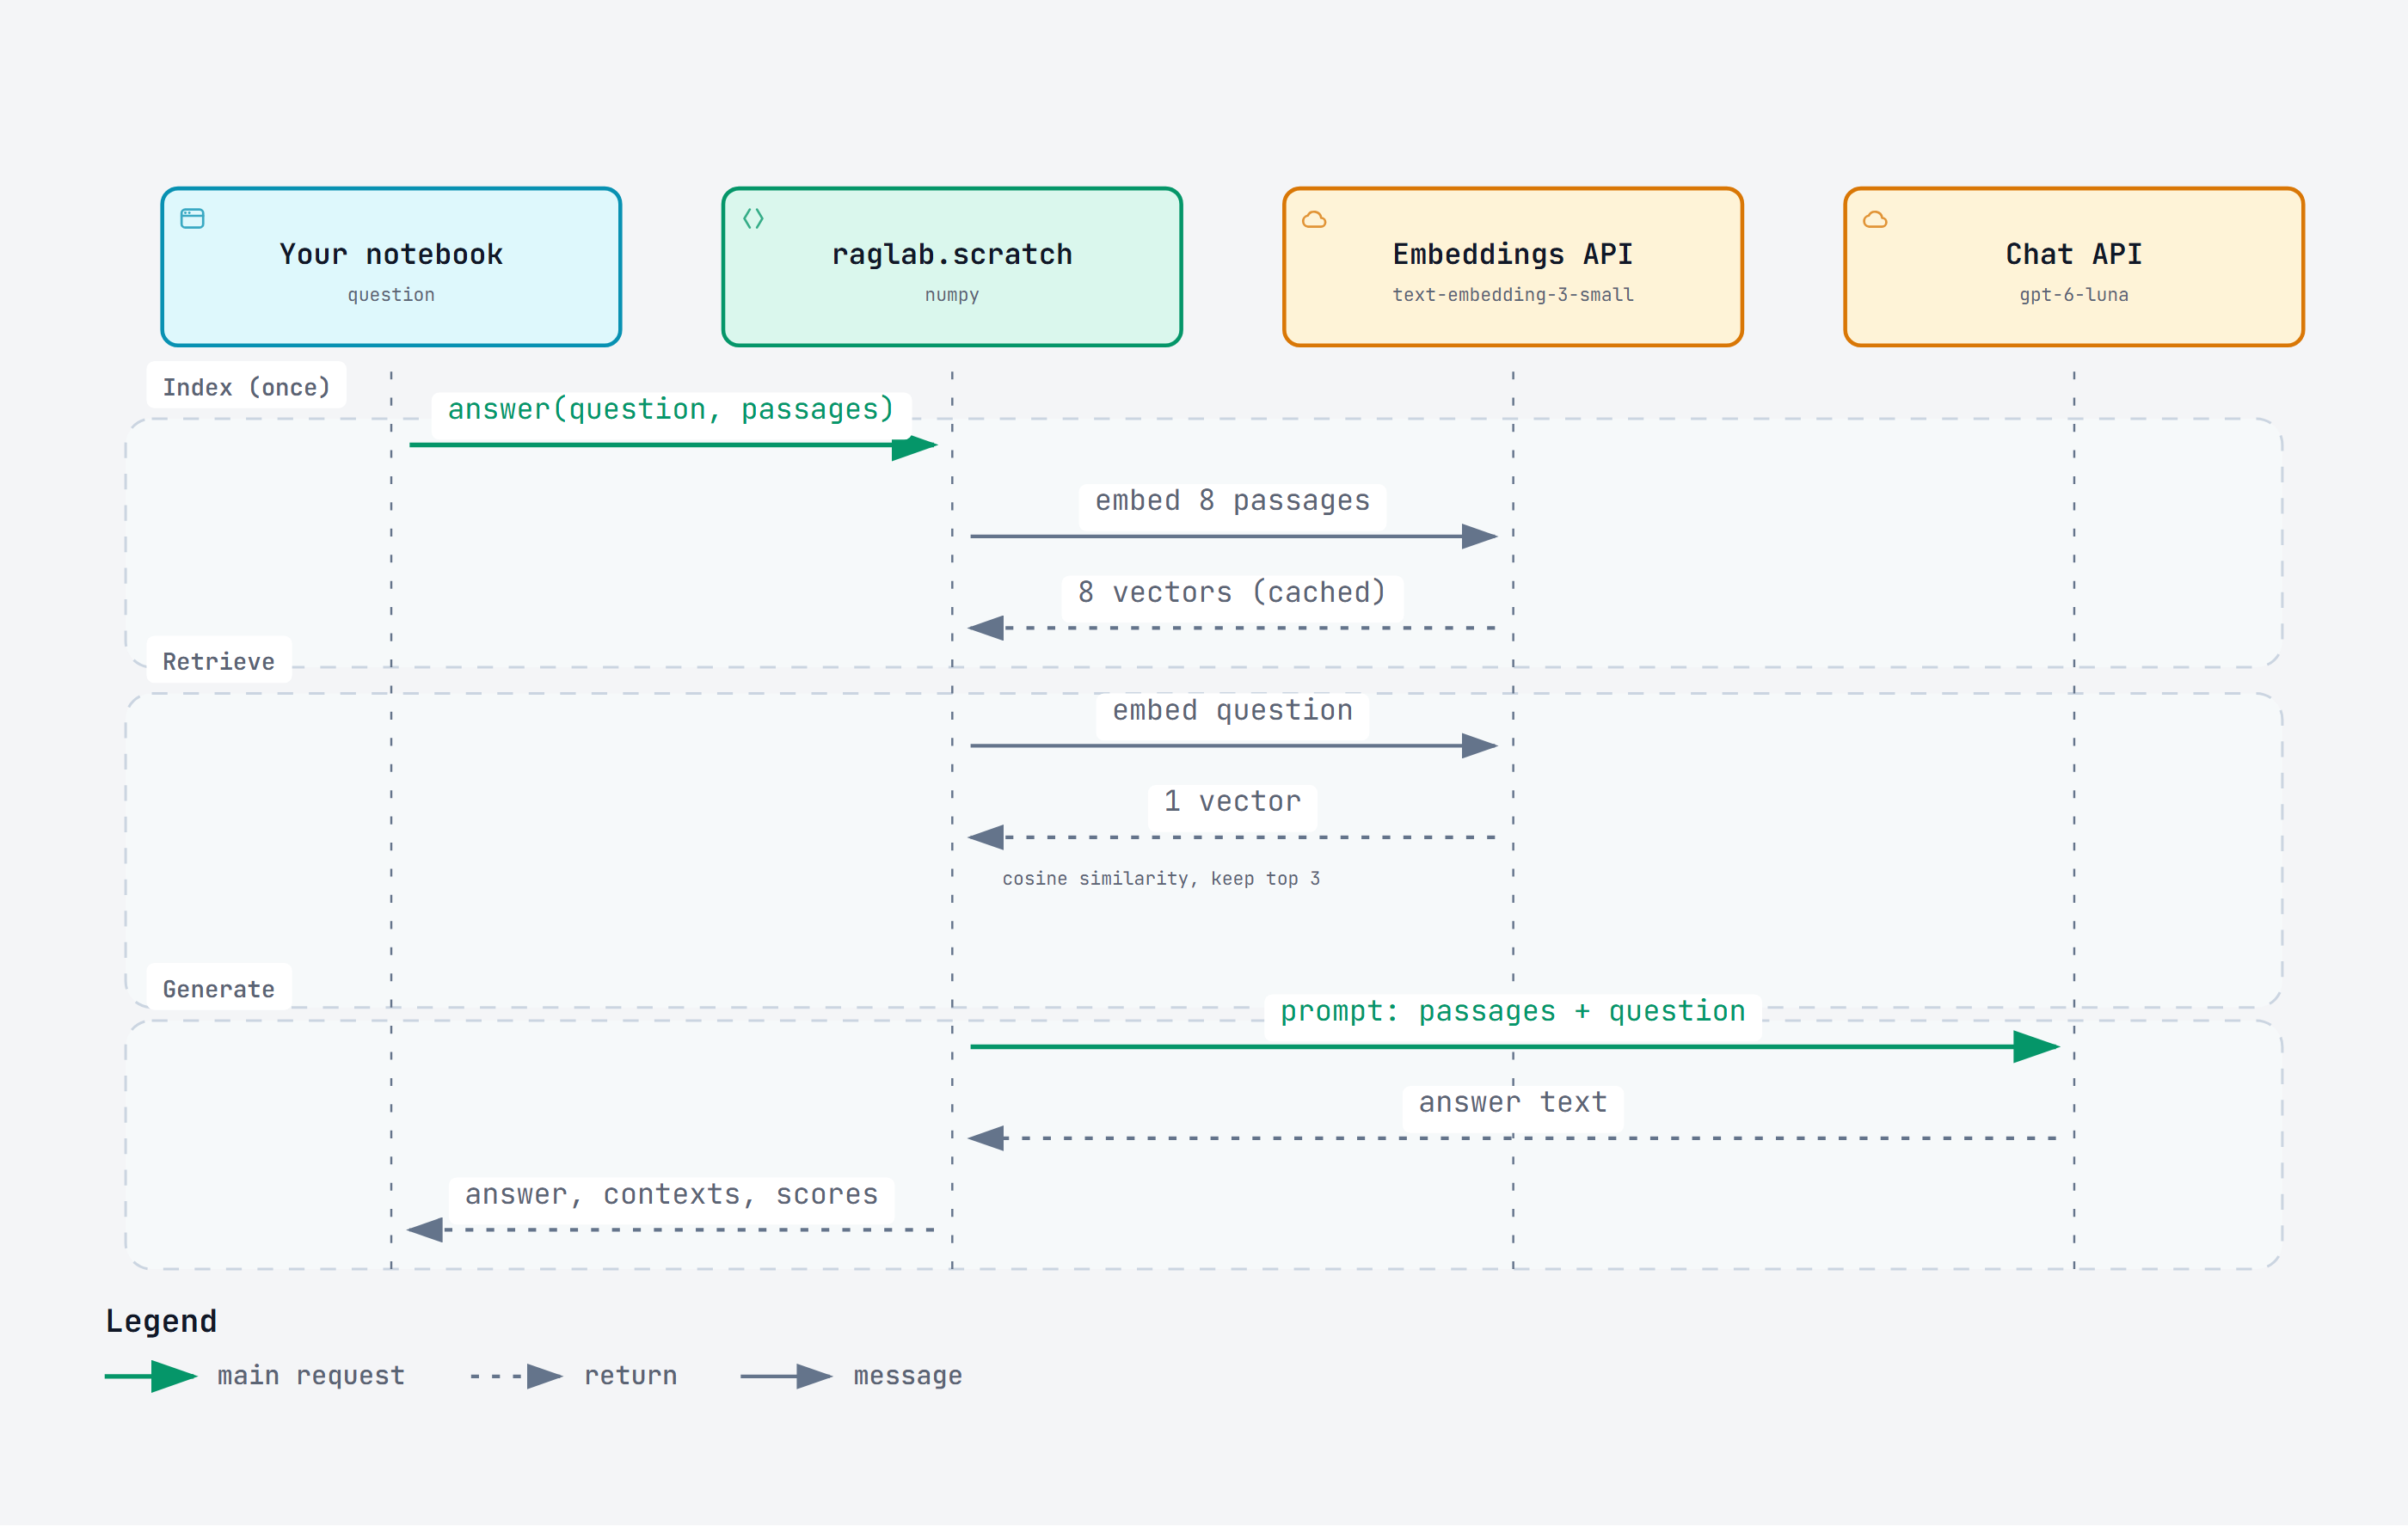

[Open interactive version](../diagrams/scratch_flow.html)

In [11]:
from raglab.display import show_diagram

show_diagram("scratch_flow")

`scratch.answer()` runs the whole loop in one call:

In [12]:
result = scratch.answer("Is Wi-Fi free?", passages, k=3)
print(result["answer"])
print([round(s, 3) for s in result["scores"]])

Yes. Wi-Fi is free for every guest at every Token Hotels & Resorts property.
[0.614, 0.153, 0.152]


## 7. When the answer isn't there

Retrieval always returns *something*: the top 3 passages exist even when none of them is
relevant. A good prompt tells the model to say so instead of guessing.

In [13]:
result = scratch.answer("Can I bring my dog to Token Lisbon?", passages, k=3)
print(result["answer"])
print("best score:", round(result["scores"][0], 3))

I don't know based on these passages.
best score: 0.563


Notice the best score: lower than for the questions that *were* answerable. Similarity scores
are a useful signal, but there's no universal cut-off; we'll measure retrieval properly in notebook 05.

## Your turn

1. Ask "Which hotels have a pool?" with `k=1` and then `k=4`. Which answer is more complete, and why?
2. Add a *distractor* passage such as `"Token Kyoto's sister hotel opens its doors at 2 PM."`
   and ask the check-in question again. Does retrieval still pick the right passage? Does the answer change?
3. Remove the "say I don't know" sentence from `scratch.PROMPT_TEMPLATE` (copy it into a new
   string first) and ask about dogs again.

<details><summary>What to expect</summary>

1. With `k=1` only one hotel's passage reaches the model, so it can name at most one pool.
   Questions that need several facts need a larger `k` (or a smarter retriever, notebook 06).
2. Similar-sounding distractors can outrank the true passage. This is why real systems
   evaluate retrieval (notebook 05) and why wording in documents matters.
3. Without the instruction, models are more likely to guess, the classic hallucination.
</details>

## Key takeaways

- Retrieval = embed the question, rank passages by cosine similarity, keep the top k.
- Generation = put those passages in the prompt and instruct the model to use only them.
- Retrieval always returns something; the prompt must handle "not in the passages".

**Added to raglab:** `scratch.cosine_sim`, `scratch.top_k`, `scratch.build_prompt`, `scratch.answer`.

In [14]:
cost.report()

model                       calls   in tokens  out tokens       USD
gpt-6-luna                      4         452          63    0.0001
total                           4                            0.0001
